# Retinal Disease Detection Using Deep Learning on OCT Images
## Step 8: Model Explainability (Grad-CAM)

**Goals**
- Implement **Grad-CAM** to visualize which image regions influence a prediction
- **Compare the highlighted regions with the original OCT scans**
- **Analyze predictions and limitations** of the model

> This notebook explains the **best model saved by Step 6** (`step6_best_model.pt` + `optimization_config.json`). Put those two files next to this notebook (in Colab: upload them in the Files pane). If they are missing, a quick ResNet18 is trained instead so the notebook still runs, but then the explanations are for that quick model, not your Step 6 model.
>
> Runtime: a few minutes, GPU optional. Run the cells once, in order.

In [ ]:
%pip install -q torch torchvision datasets pillow matplotlib seaborn pandas numpy

In [ ]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

# Folder that CONTAINS "zacharielegault___kermany2017-oct" (your Hugging Face "datasets" cache folder).
# Leave as None on Colab or if the default location works.
HF_CACHE_DIR = None
if HF_CACHE_DIR:
    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["HF_DATASETS_OFFLINE"] = "1"

In [ ]:
import glob
import gc
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from datasets import load_dataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
sns.set_style("white")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

MODEL_FILE, CONFIG_FILE = "step6_best_model.pt", "optimization_config.json"
HAVE_STEP6 = os.path.exists(MODEL_FILE) and os.path.exists(CONFIG_FILE)
if HAVE_STEP6:
    with open(CONFIG_FILE) as f:
        cfg6 = json.load(f)
    print("Loaded Step 6 config. Best model:", cfg6["best_model"])
else:
    cfg6 = None
    print("Step 6 files not found -> a quick ResNet18 will be trained as a stand-in (see 8.2).")

torch 2.14.1+cpu | device: cpu
Step 6 files not found -> a quick ResNet18 will be trained as a stand-in (see 8.2).


## 8.1 Data
The test split is used here because explanations are most informative on scans the model did not train on. Images are resized to the size the model was trained with (`img_size` in the Step 6 config, else 112). Original full-resolution scans are loaded from the dataset only for display.

In [ ]:
IMG_SIZE = int(cfg6["img_size"]) if cfg6 else 112
dataset = load_dataset("zacharielegault/Kermany2017-OCT", cache_dir=HF_CACHE_DIR)
train_data, test_data = dataset["train"], dataset["test"]
class_names = cfg6["class_names"] if cfg6 else train_data.features["label"].names
n_classes = len(class_names)
test_labels_all = test_data.data.column("label").to_numpy()
print("Classes:", class_names, "| IMG_SIZE:", IMG_SIZE)

def resize_all(ds, idx, size):
    arr = np.empty((len(idx), size, size), dtype=np.uint8)
    t0 = time.time()
    for k, i in enumerate(idx):
        arr[k] = np.asarray(ds[int(i)]["image"].convert("L").resize((size, size), Image.BILINEAR))
        if (k + 1) % 250 == 0 or k + 1 == len(idx):
            print(f"  resized {k + 1}/{len(idx)} ({time.time() - t0:.0f}s)", flush=True)
    return arr

# Reuse the cache written by Steps 5-6 (same test order as the dataset); otherwise resize the test split now.
caches = sorted(glob.glob(f"oct_cache_tl_{IMG_SIZE}_*_{SEED}.npz"))
if caches:
    z = np.load(caches[0])
    X_test, y_test = z["X_test"], z["y_test"]
    X_pool, y_pool = z["X_pool"], z["y_pool"]
    print("Loaded", caches[0])
else:
    X_test, y_test = resize_all(test_data, np.arange(len(test_data)), IMG_SIZE), test_labels_all
    X_pool = y_pool = None
assert len(X_test) == len(test_data), "cached test set does not match the dataset"
print("test", X_test.shape)

PIX_MEAN = float(cfg6["pixel_mean"]) if cfg6 else None
PIX_STD = float(cfg6["pixel_std"]) if cfg6 else None
IM_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IM_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
FILL = float(X_test.mean())                  # grey level used to "erase" pixels in 8.7

Generating train split:   0%|          | 0/108309 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL'] | IMG_SIZE: 112
  resized 250/1000 (2s)
  resized 500/1000 (3s)
  resized 750/1000 (4s)
  resized 1000/1000 (5s)
test (1000, 112, 112)


## 8.2 Load the model
The architecture is rebuilt exactly as in Step 6 and the saved weights are loaded (no internet download needed). ReLU layers are switched to non-in-place so the gradient hooks used by Grad-CAM are safe.

In [ ]:
def make_act(): return nn.ReLU()

class OCTCNN(nn.Module):
    """The Step 4 / Step 6 custom CNN (4 conv blocks, global average pooling, small classifier)."""
    def __init__(self, n_classes=4, in_channels=1, width=16, bn=True, dropout=0.4, conv_dropout=0.0, fc=128):
        super().__init__()
        channels = (width, 2 * width, 4 * width, 8 * width)
        layers, c_in = [], in_channels
        for c_out in channels:
            layers += [nn.Conv2d(c_in, c_out, 3, padding=1, bias=not bn)]
            if bn: layers += [nn.BatchNorm2d(c_out)]
            layers += [make_act(), nn.MaxPool2d(2)]
            if conv_dropout > 0: layers += [nn.Dropout2d(conv_dropout)]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(c_in, fc), make_act(), nn.Dropout(dropout), nn.Linear(fc, n_classes))
    def forward(self, x):
        return self.classifier(self.gap(self.features(x)))

def head_module(m, arch):
    return {"resnet18": lambda: m.fc, "vgg16": lambda: m.classifier[6],
            "mobilenet_v2": lambda: m.classifier[1], "densenet121": lambda: m.classifier}[arch]()

def set_head(m, arch, new):
    if arch == "resnet18": m.fc = new
    elif arch == "vgg16": m.classifier[6] = new
    elif arch == "mobilenet_v2": m.classifier[1] = new
    elif arch == "densenet121": m.classifier = new

def build_pretrained(arch, dropout=0.0, weights="DEFAULT"):
    m = getattr(models, arch)(weights=weights)
    lin = nn.Linear(head_module(m, arch).in_features, n_classes)
    set_head(m, arch, nn.Sequential(nn.Dropout(dropout), lin) if dropout > 0 else lin)
    return m

def no_inplace(model):
    for mod in model.modules():
        if isinstance(mod, (nn.ReLU, nn.ReLU6)): mod.inplace = False
    return model

def target_layer(model, arch):
    """Last convolutional feature map: the usual Grad-CAM target."""
    return {"custom_cnn": lambda: model.features, "resnet18": lambda: model.layer4[-1],
            "mobilenet_v2": lambda: model.features[-1], "vgg16": lambda: model.features[29],
            "densenet121": lambda: model.features.denseblock4}[arch]()

def build_model(weights="DEFAULT"):
    """A fresh, untrained copy of the architecture that is being explained."""
    if HAVE_STEP6 and cfg6["kind"] == "custom":
        h = cfg6["hyperparameters"]
        return OCTCNN(n_classes, 1, h.get("width", 16), h.get("bn", True), h.get("dropout", 0.4), h.get("conv_dropout", 0.0), h.get("fc", 128))
    if HAVE_STEP6:
        return build_pretrained(cfg6["architecture"], cfg6["hyperparameters"].get("dropout", 0.0), weights=None)
    return build_pretrained("resnet18", 0.0, weights=weights)

if HAVE_STEP6:
    arch, RGB, model_name = cfg6["architecture"], cfg6["kind"] != "custom", cfg6["best_model"]
    model = build_model()
    model.load_state_dict(torch.load(MODEL_FILE, map_location="cpu"))
else:
    arch, RGB, model_name = "resnet18", True, "ResNet18 (quick stand-in)"
    if X_pool is None:                          # no cache at all: take a small balanced training sample from the dataset
        tl = train_data.data.column("label").to_numpy()
        pick = np.concatenate([rng.choice(np.where(tl == c)[0], 400, replace=False) for c in range(n_classes)])
        pick = rng.permutation(pick)
        X_pool, y_pool = resize_all(train_data, pick, IMG_SIZE), tl[pick]
    model = build_model()
model = no_inplace(model).to(device)
print("Model:", model_name, "| parameters:", sum(p.numel() for p in model.parameters()))

  resized 250/1600 (1s)
  resized 500/1600 (3s)
  resized 750/1600 (4s)
  resized 1000/1600 (6s)
  resized 1250/1600 (7s)
  resized 1500/1600 (9s)
  resized 1600/1600 (9s)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


Model: ResNet18 (quick stand-in) | parameters: 11178564


In [ ]:
def prep(imgs_uint8):
    """uint8 (N, H, W) -> normalized tensor exactly as the model was trained."""
    x = torch.from_numpy(imgs_uint8).float().div(255.0).unsqueeze(1)
    if RGB:
        return (x.repeat(1, 3, 1, 1) - IM_MEAN) / IM_STD
    return (x - PIX_MEAN) / PIX_STD

@torch.no_grad()
def predict_probs(m, imgs, bs=128):
    m.eval()
    return torch.cat([m(prep(imgs[i:i + bs]).to(device)).softmax(1).cpu() for i in range(0, len(imgs), bs)]).numpy()

if not HAVE_STEP6:        # quick stand-in training: 3 epochs, new head learns faster than the pretrained body
    head = head_module(model, "resnet18")
    hid = {id(p) for p in head.parameters()}
    opt = torch.optim.Adam([{"params": list(head.parameters()), "lr": 1e-3},
                            {"params": [p for p in model.parameters() if id(p) not in hid], "lr": 1e-4}])
    for ep in range(3):
        model.train()
        order = rng.permutation(len(X_pool))
        for i in range(0, len(order), 32):
            b = order[i:i + 32]
            x = prep(X_pool[b]).to(device); y = torch.from_numpy(y_pool[b]).long().to(device)
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        print(f"stand-in epoch {ep + 1} done, last batch loss {loss.item():.3f}")

probs_test = predict_probs(model, X_test)
pred_test = probs_test.argmax(1)
conf_test = probs_test.max(1)
correct = pred_test == y_test
cm = np.zeros((n_classes, n_classes), dtype=int); np.add.at(cm, (y_test, pred_test), 1)
rec = cm.diagonal() / cm.sum(1); prec = cm.diagonal() / np.maximum(cm.sum(0), 1)
f1 = float((2 * prec * rec / np.maximum(prec + rec, 1e-12)).mean())
print(f"Test accuracy {correct.mean():.3f} | macro-F1 {f1:.3f}   (compare with Step 6)")
print("Per-class recall:", {c: round(float(r), 3) for c, r in zip(class_names, rec)})

stand-in epoch 1 done, last batch loss 0.604
stand-in epoch 2 done, last batch loss 0.356
stand-in epoch 3 done, last batch loss 0.130
Test accuracy 0.848 | macro-F1 0.845   (compare with Step 6)
Per-class recall: {'CNV': 0.896, 'DME': 1.0, 'DRUSEN': 0.708, 'NORMAL': 0.788}


## 8.3 Grad-CAM
**Idea.** Take the last convolutional feature maps `A_k` (the last place where the network still has spatial layout). For a target class `c`, compute how much the class score `y_c` changes with each map: the gradient `dy_c/dA_k`, averaged over positions gives a weight `a_k`. The heatmap is

`L = ReLU( sum_k a_k * A_k )`

a coarse map (as small as the feature map, e.g. 7 x 7) showing where evidence **for class `c`** is. It is upsampled to the image size and scaled to 0-1 for display. Red = strong evidence for the class, blue = little.

Important: Grad-CAM shows *where the model looked*, not *why* it decided or whether the region is clinically meaningful. We test this in 8.7.

In [8]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.act, self.grad = model, None, None
        layer.register_forward_hook(self._fwd)
    def _fwd(self, module, inp, out):
        if out.requires_grad:                      # only while Grad-CAM is computing gradients (not in plain predictions)
            self.act = out
            out.register_hook(lambda g: setattr(self, "grad", g))
    def __call__(self, x, class_idx=None):
        """x: normalized batch. Returns CAM (N, H, W) in [0, 1], probabilities, and the class explained."""
        self.model.eval()
        x = x.to(device)
        with torch.enable_grad():
            out = self.model(x)
            idx = out.argmax(1) if class_idx is None else torch.as_tensor(class_idx, device=device).expand(len(x)).clone()
            self.model.zero_grad(set_to_none=True)
            out.gather(1, idx[:, None]).sum().backward()
        w = self.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.act).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        flat = cam.flatten(1)
        mn, mx = flat.min(1)[0][:, None, None], flat.max(1)[0][:, None, None]
        cam = (cam - mn) / (mx - mn + 1e-8)
        return cam.detach().cpu().numpy(), out.softmax(1).detach().cpu().numpy(), idx.cpu().numpy()

gradcam = GradCAM(model, target_layer(model, arch))

def explain(imgs, class_idx=None, bs=64):
    cams, probs, idxs = [], [], []
    for i in range(0, len(imgs), bs):
        c, p, k = gradcam(prep(imgs[i:i + bs]), class_idx)
        cams.append(c); probs.append(p); idxs.append(k)
    return np.concatenate(cams), np.concatenate(probs), np.concatenate(idxs)

cam, p, k = explain(X_test[:4])
print("CAM shape", cam.shape, "| value range", cam.min().round(2), "-", cam.max().round(2), "| explained classes", [class_names[i] for i in k])

CAM shape (4, 112, 112) | value range 0.0 - 1.0 | explained classes ['CNV', 'CNV', 'CNV', 'CNV']


In [9]:
# helpers to draw the original scan, the heatmap and the overlay
SHOW = 256
def original(i):
    return np.asarray(test_data[int(i)]["image"].convert("L").resize((SHOW, SHOW), Image.BILINEAR))

def up(cam):
    return np.asarray(Image.fromarray((cam * 255).astype(np.uint8)).resize((SHOW, SHOW), Image.BILINEAR)) / 255.0

def show_overlay(ax, gray, cam_up, alpha=0.45):
    ax.imshow(gray, cmap="gray", vmin=0, vmax=255)
    ax.imshow(cam_up, cmap="jet", alpha=alpha, vmin=0, vmax=1)
    ax.axis("off")

## 8.4 Grad-CAM on example scans, compared with the original image
For every class, the three **correctly classified scans with the highest confidence**. Columns: the original scan, the Grad-CAM heatmap, and the heatmap overlaid on the scan. The model is asked to explain its **own prediction**.

What a clinician would expect to see (general OCT knowledge, not something this dataset annotates):

| Class | Typical OCT appearance |
|---|---|
| **CNV** | fluid or a bulge of new vessels at/under the retina, often near the fovea, irregular retinal layers |
| **DME** | fluid-filled cysts inside the retina and thickening of the macula |
| **DRUSEN** | small bumps/deposits under the retinal pigment layer (the bright band at the bottom of the retina) |
| **NORMAL** | smooth foveal dip, regular layers, no fluid or deposits |

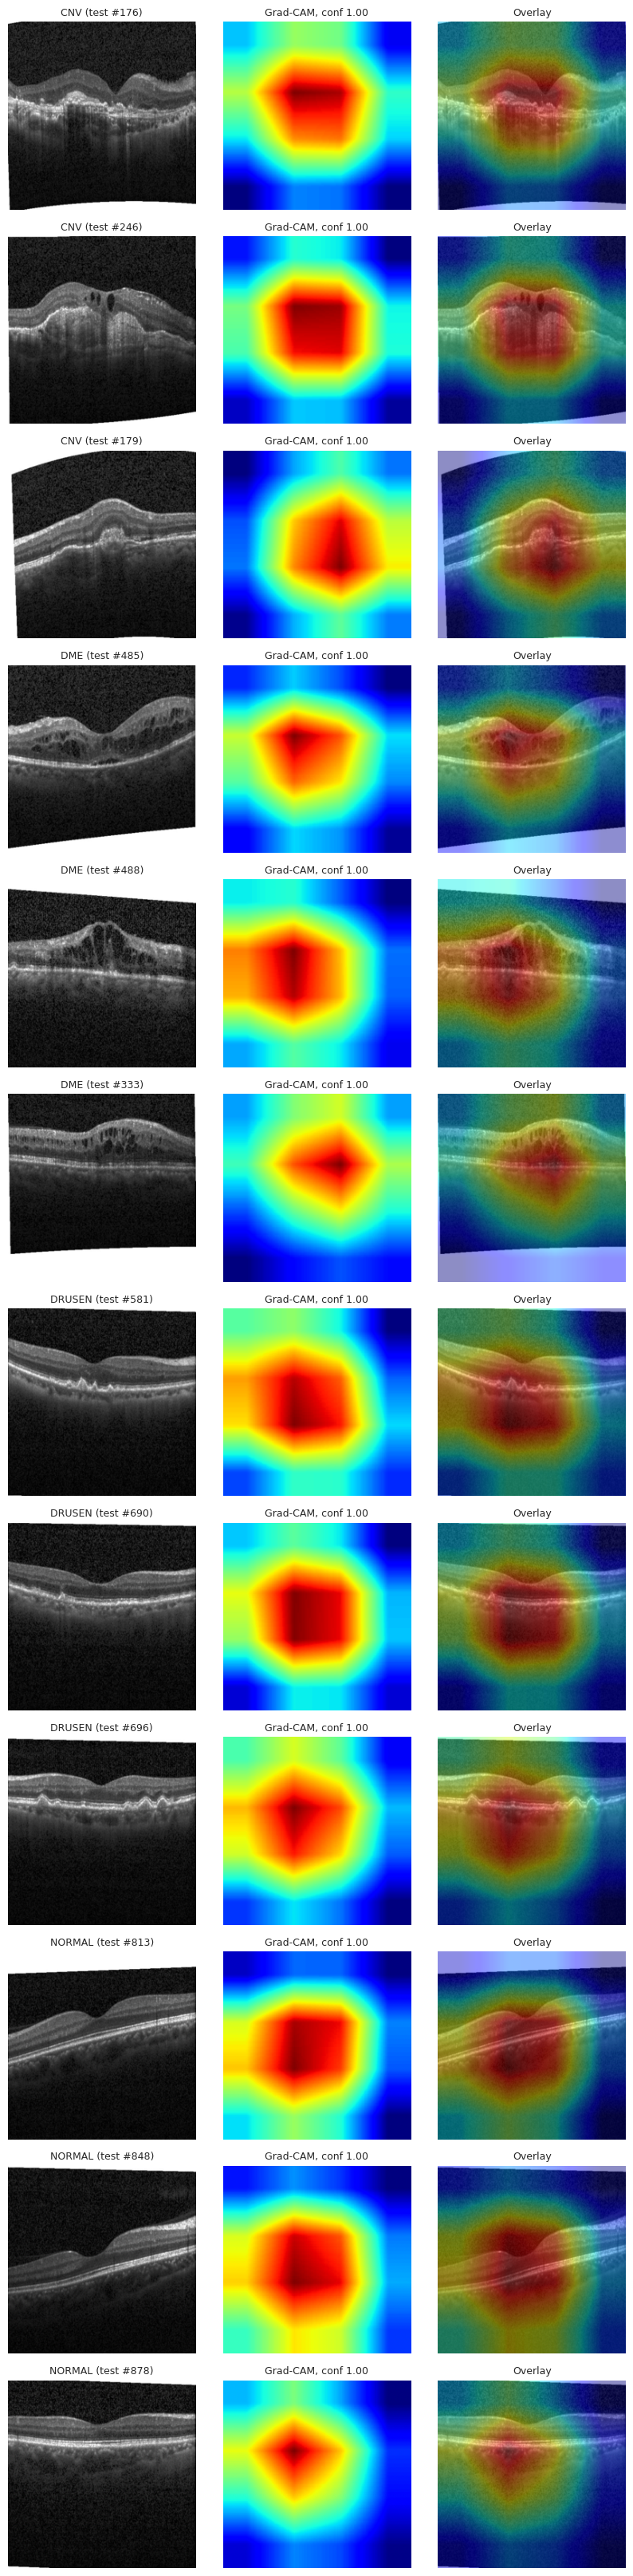

In [10]:
N_SHOW = 3
chosen = []
for c in range(n_classes):
    cand = np.where((y_test == c) & correct)[0]
    chosen += list(cand[np.argsort(-conf_test[cand])][:N_SHOW])
cams_sel, probs_sel, _ = explain(X_test[chosen])

fig, axes = plt.subplots(len(chosen), 3, figsize=(8.4, 2.7 * len(chosen)))
for r, (i, cm_) in enumerate(zip(chosen, cams_sel)):
    g = original(i)
    axes[r, 0].imshow(g, cmap="gray"); axes[r, 0].axis("off")
    axes[r, 0].set_title(f"{class_names[y_test[i]]} (test #{i})", fontsize=9)
    axes[r, 1].imshow(up(cm_), cmap="jet", vmin=0, vmax=1); axes[r, 1].axis("off")
    axes[r, 1].set_title(f"Grad-CAM, conf {conf_test[i]:.2f}", fontsize=9)
    show_overlay(axes[r, 2], g, up(cm_)); axes[r, 2].set_title("Overlay", fontsize=9)
plt.tight_layout(); plt.show()

**How to read it:** is the red region on the retina, and on the part of the retina where the disease would be (fluid, bulge, deposits under the pigment layer)? Or is it on the dark background, the edges, or other irrelevant parts? Judge each class by eye here, then measure it in 8.5.

## 8.5 Do the highlighted regions fall on retinal tissue?
Without pixel-level annotations we cannot measure agreement with a doctor, but we can check something basic: **is the heat on the retina rather than on the dark background?**

1. Segment tissue from background with a simple intensity threshold (Otsu) on a blurred image.
2. For each scan compute `focus ratio = (share of CAM heat inside tissue) / (share of the image that is tissue)`. A ratio of 1 means the heat is spread like the tissue is (no preference); well above 1 means it concentrates on tissue; below 1 means it sits on the background.

We also average the heatmap over all correctly classified scans of each class to see where each class's evidence typically is.

,scans,tissue_share,heat_in_tissue,focus_ratio,peak_on_tissue
class,,,,,
CNV,40,0.202,0.203,0.871,0.400
DME,40,0.197,0.207,0.919,0.300
DRUSEN,40,0.205,0.207,0.897,0.425
NORMAL,40,0.207,0.244,1.128,0.650


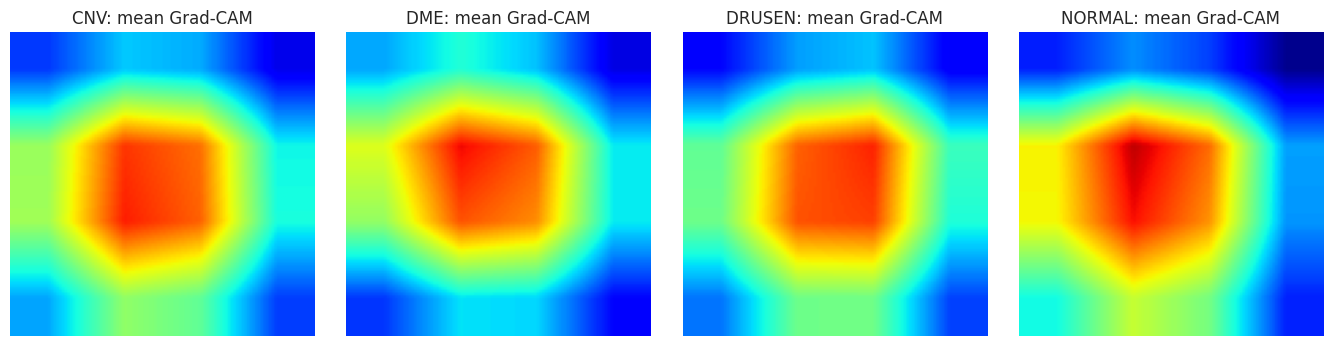

In [11]:
def otsu_mask(img):
    blur = np.asarray(Image.fromarray(img).filter(__import__("PIL.ImageFilter", fromlist=["x"]).GaussianBlur(2)))
    hist, _ = np.histogram(blur, bins=256, range=(0, 256))
    p = hist / hist.sum(); omega = np.cumsum(p); mu = np.cumsum(p * np.arange(256))
    sb = (mu[-1] * omega - mu) ** 2 / np.maximum(omega * (1 - omega), 1e-12)
    return blur > np.argmax(sb)

# explain every correctly classified test scan of up to N_AN scans per class (the explained class is the prediction)
N_AN = 40
an_idx = np.concatenate([np.where((y_test == c) & correct)[0][:N_AN] for c in range(n_classes)])
cams_an, probs_an, _ = explain(X_test[an_idx])

rows = []
for j, i in enumerate(an_idx):
    mask = otsu_mask(X_test[i])
    heat = cams_an[j]
    rows.append({"class": class_names[y_test[i]], "tissue share": mask.mean(),
                 "heat in tissue": float((heat * mask).sum() / max(heat.sum(), 1e-8)),
                 "peak in tissue": bool(mask.flat[heat.argmax()])})
loc = pd.DataFrame(rows)
loc["focus ratio"] = loc["heat in tissue"] / loc["tissue share"].clip(lower=1e-3)
display(loc.groupby("class").agg(scans=("focus ratio", "size"), tissue_share=("tissue share", "mean"), heat_in_tissue=("heat in tissue", "mean"),
                                 focus_ratio=("focus ratio", "mean"), peak_on_tissue=("peak in tissue", "mean")).round(3))

fig, axes = plt.subplots(1, n_classes, figsize=(3.4 * n_classes, 3.4))
for c, ax in enumerate(np.atleast_1d(axes)):
    sel = np.array([y_test[i] == c for i in an_idx])
    ax.axis("off")
    if sel.any():
        ax.imshow(cams_an[sel].mean(0), cmap="jet", vmin=0, vmax=1); ax.set_title(f"{class_names[c]}: mean Grad-CAM")
    else:
        ax.set_title(f"{class_names[c]}: no correct scans")
plt.tight_layout(); plt.show()

**What to look for:** a focus ratio clearly above 1 and a high share of peaks on tissue mean the model attends to the retina. Differences between the class-average maps show whether the model looks in different places for different diseases (for example, near the bottom retinal layers for DRUSEN) or at the same central region for everything, which would suggest a generic "retina is here" cue.

## 8.6 Analyzing predictions: errors, confidence and what the model looks at when it is wrong
**Misclassified scans.** For the most confidently wrong predictions we show Grad-CAM for the **predicted** class and for the **true** class. If the true-class map highlights the lesion while the predicted-class map highlights something else, the model "saw" evidence but was outweighed.

152 misclassified test scans out of 1000


,pred CNV,pred DME,pred DRUSEN,pred NORMAL
true CNV,224,25,1,0
true DME,0,250,0,0
true DRUSEN,52,11,177,10
true NORMAL,1,16,36,197


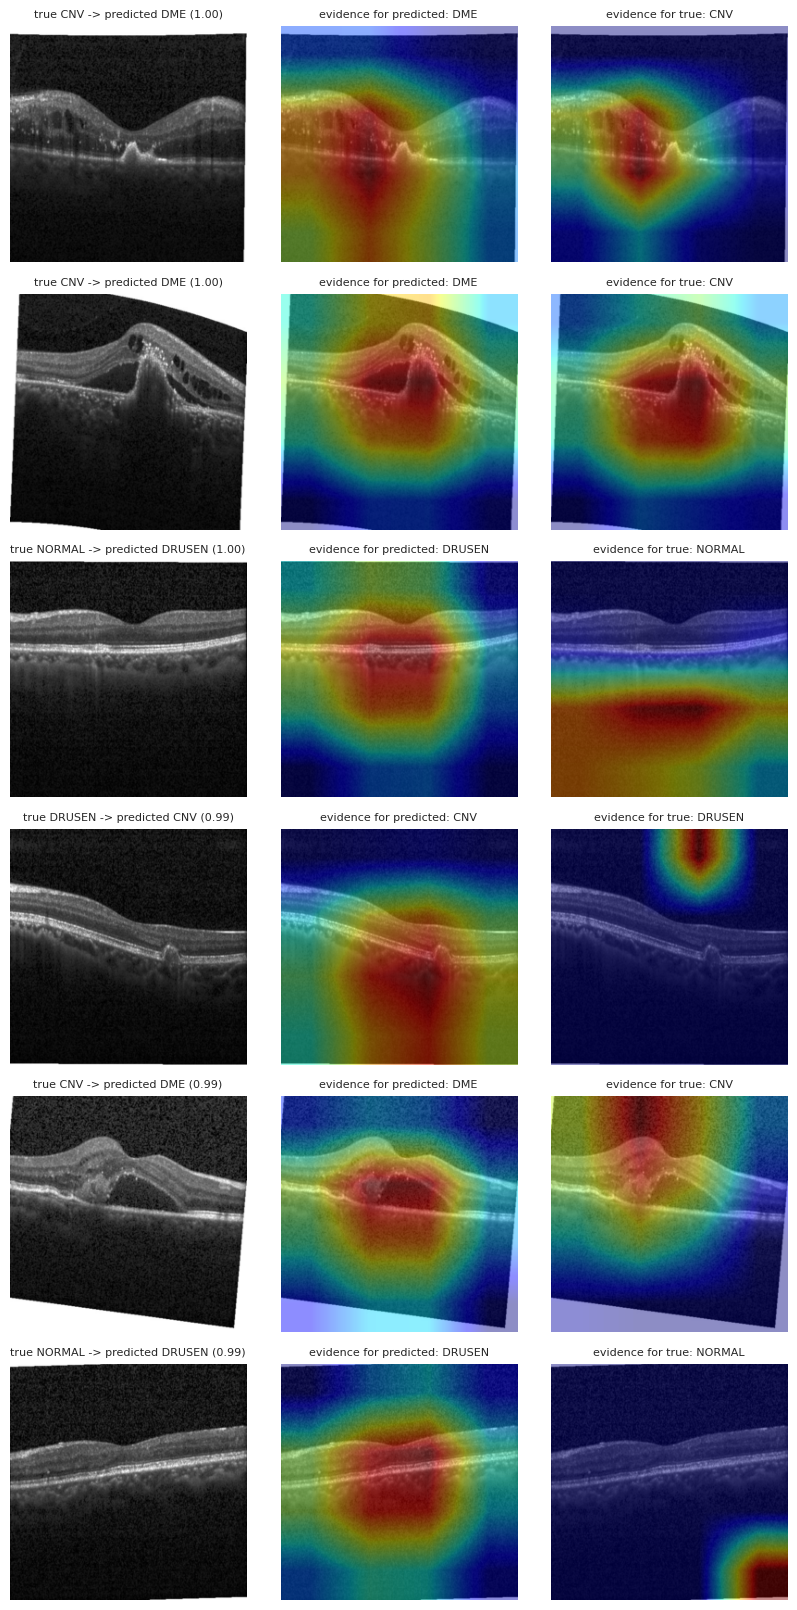

In [12]:
wrong = np.where(~correct)[0]
print(f"{len(wrong)} misclassified test scans out of {len(y_test)}")
display(pd.DataFrame(cm, index=[f"true {c}" for c in class_names], columns=[f"pred {c}" for c in class_names]))

if len(wrong):
    w = wrong[np.argsort(-conf_test[wrong])][:6]
    cam_pred, _, _ = explain(X_test[w], pred_test[w][0] if False else None)
    cam_true = np.concatenate([explain(X_test[[i]], int(y_test[i]))[0] for i in w])
    fig, axes = plt.subplots(len(w), 3, figsize=(8.4, 2.7 * len(w)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(w):
        g = original(i)
        axes[r, 0].imshow(g, cmap="gray"); axes[r, 0].axis("off")
        axes[r, 0].set_title(f"true {class_names[y_test[i]]} -> predicted {class_names[pred_test[i]]} ({conf_test[i]:.2f})", fontsize=8)
        show_overlay(axes[r, 1], g, up(cam_pred[r])); axes[r, 1].set_title(f"evidence for predicted: {class_names[pred_test[i]]}", fontsize=8)
        show_overlay(axes[r, 2], g, up(cam_true[r])); axes[r, 2].set_title(f"evidence for true: {class_names[y_test[i]]}", fontsize=8)
    plt.tight_layout(); plt.show()

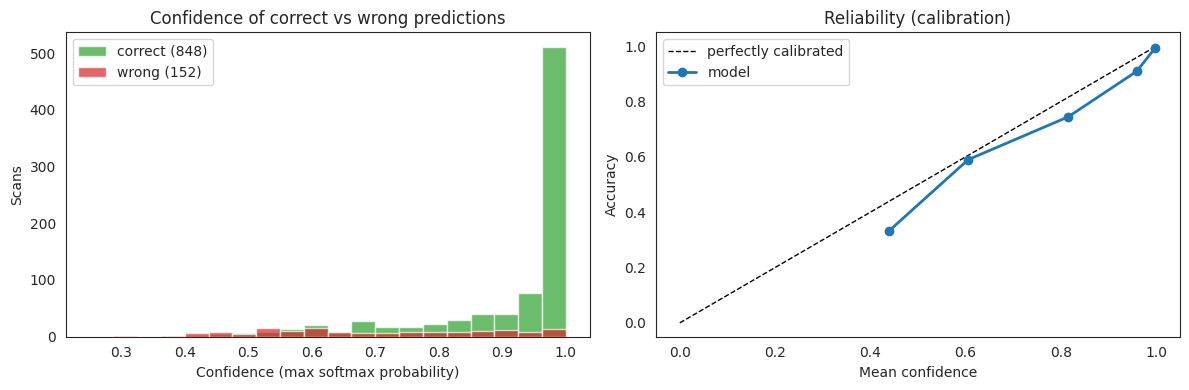

,confidence,scans,mean confidence,accuracy
0,0.00-0.50,30,0.440,0.333
1,0.50-0.70,139,0.605,0.590
2,0.70-0.90,184,0.815,0.745
3,0.90-0.99,276,0.959,0.909
4,0.99-1.00,371,0.997,0.992


,class,scans,recall,precision,mean confidence (correct),mean confidence (wrong)
0,CNV,250,0.896,0.809,0.931,0.753
1,DME,250,1.000,0.828,0.969,NaN
2,DRUSEN,250,0.708,0.827,0.866,0.729
3,NORMAL,250,0.788,0.952,0.866,0.651


In [13]:
# Confidence: is the model more sure when it is right? Is that confidence trustworthy?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(conf_test[correct], bins=20, range=(0.25, 1), alpha=0.7, label=f"correct ({correct.sum()})", color="tab:green")
if (~correct).any(): axes[0].hist(conf_test[~correct], bins=20, range=(0.25, 1), alpha=0.7, label=f"wrong ({(~correct).sum()})", color="tab:red")
axes[0].set_xlabel("Confidence (max softmax probability)"); axes[0].set_ylabel("Scans"); axes[0].legend(); axes[0].set_title("Confidence of correct vs wrong predictions")

bins = np.array([0.0, 0.5, 0.7, 0.9, 0.99, 1.0001])
rows = []
for a, b in zip(bins[:-1], bins[1:]):
    s = (conf_test >= a) & (conf_test < b)
    if s.sum(): rows.append({"confidence": f"{a:.2f}-{min(b, 1):.2f}", "scans": int(s.sum()), "mean confidence": conf_test[s].mean(), "accuracy": correct[s].mean()})
rel = pd.DataFrame(rows)
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
axes[1].plot(rel["mean confidence"], rel["accuracy"], "o-", lw=2, label="model")
axes[1].set_xlabel("Mean confidence"); axes[1].set_ylabel("Accuracy"); axes[1].set_title("Reliability (calibration)"); axes[1].legend()
plt.tight_layout(); plt.show()
display(rel.round(3))

per_class = pd.DataFrame({"class": class_names, "scans": cm.sum(1), "recall": rec, "precision": prec,
                          "mean confidence (correct)": [conf_test[(y_test == c) & correct].mean() if ((y_test == c) & correct).any() else np.nan for c in range(n_classes)],
                          "mean confidence (wrong)": [conf_test[(y_test == c) & ~correct].mean() if ((y_test == c) & ~correct).any() else np.nan for c in range(n_classes)]})
display(per_class.round(3))

## 8.7 Can we trust the heatmaps? Two sanity checks
A heatmap that looks plausible is not proof that it reflects what the model uses. Two standard checks:

**A. Deletion test (faithfulness).** Erase the pixels Grad-CAM says matter most (replace them by the mean grey level) and watch the model's confidence in its original prediction. If the heatmap is faithful, erasing the *most* highlighted pixels should hurt much more than erasing the same number of *random* pixels, and erasing the *least* highlighted pixels should hurt least.

**B. Randomization test.** Re-initialize the final classification layer (random weights) and recompute the heatmaps. If a heatmap barely changes, it depends on the image structure more than on what the trained model learned, so it is not explaining the model. We report the rank correlation between the original and the randomized heatmaps (1 = identical, 0 = unrelated).

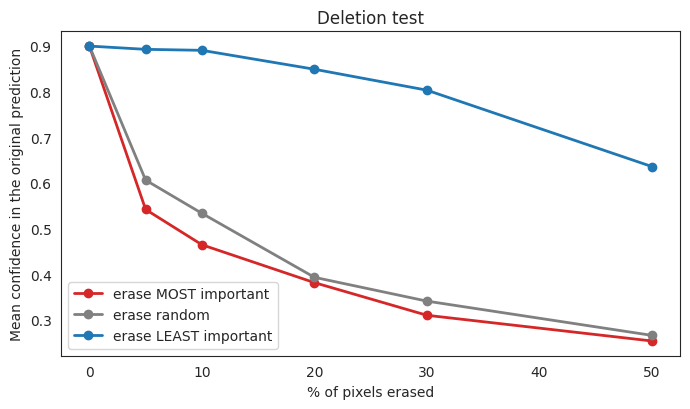

,% erased,most important (Grad-CAM),random pixels,least important (Grad-CAM)
0,5.0,0.542,0.606,0.893
1,10.0,0.464,0.533,0.890
2,20.0,0.381,0.393,0.849
3,30.0,0.310,0.341,0.803
4,50.0,0.253,0.266,0.636


In [14]:
imgs_d = X_test[an_idx]
cams_d, probs_d, pred_d = explain(imgs_d)
N, H, W = cams_d.shape
base = probs_d[np.arange(N), pred_d]

def prob_after(masks):
    x = imgs_d.copy(); x[masks] = int(FILL)
    return predict_probs(model, x)[np.arange(N), pred_d]

order = np.argsort(cams_d.reshape(N, -1) + 1e-9 * rng.random((N, H * W)), axis=1)         # ascending importance
rand_rank = np.argsort(rng.random((N, H * W)), axis=1)
fracs = [0.05, 0.10, 0.20, 0.30, 0.50]
res = {"most important (Grad-CAM)": [], "random pixels": [], "least important (Grad-CAM)": []}
for fr in fracs:
    k = int(fr * H * W)
    for name, ranking, tail in [("most important (Grad-CAM)", order, True), ("random pixels", rand_rank, True), ("least important (Grad-CAM)", order, False)]:
        m = np.zeros((N, H * W), dtype=bool)
        sel = ranking[:, -k:] if tail else ranking[:, :k]
        np.put_along_axis(m, sel, True, axis=1)
        res[name].append(float(prob_after(m.reshape(N, H, W)).mean()))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot([0] + [f * 100 for f in fracs], [float(base.mean())] + res["most important (Grad-CAM)"], "o-", lw=2, color="tab:red", label="erase MOST important")
ax.plot([0] + [f * 100 for f in fracs], [float(base.mean())] + res["random pixels"], "o-", lw=2, color="gray", label="erase random")
ax.plot([0] + [f * 100 for f in fracs], [float(base.mean())] + res["least important (Grad-CAM)"], "o-", lw=2, color="tab:blue", label="erase LEAST important")
ax.set_xlabel("% of pixels erased"); ax.set_ylabel("Mean confidence in the original prediction"); ax.set_title("Deletion test"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame({"% erased": [f * 100 for f in fracs], **{k: v for k, v in res.items()}}).round(3))

Rank correlation, trained vs randomized final layer: mean 0.34 (median 0.45)


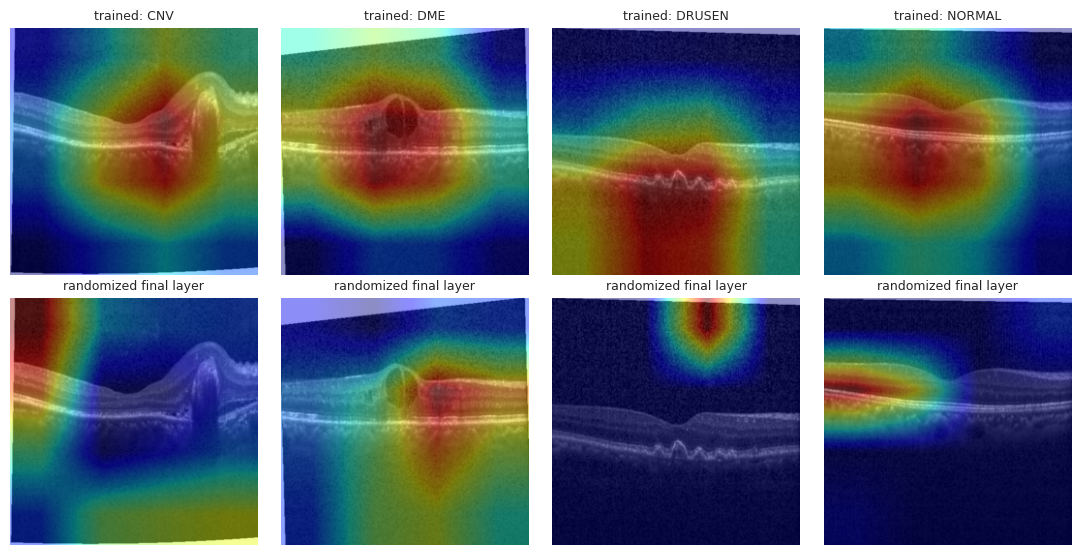

132516

In [15]:
# B. randomization of the final classification layer
import copy
rand_model = no_inplace(build_model(weights=None)).to(device)
rand_model.load_state_dict(model.state_dict())
last_linear = [m for m in rand_model.modules() if isinstance(m, nn.Linear)][-1]
torch.manual_seed(SEED + 7)
nn.init.kaiming_normal_(last_linear.weight); nn.init.zeros_(last_linear.bias)
rand_cam = GradCAM(rand_model, target_layer(rand_model, arch))

def rank(a): return np.argsort(np.argsort(a))
corr = []
for i in range(0, len(imgs_d), 64):
    x = prep(imgs_d[i:i + 64])
    c_rand, _, _ = rand_cam(x, pred_d[i:i + 64])          # explain the SAME class as the trained model did
    for a, b in zip(cams_d[i:i + 64], c_rand):
        corr.append(np.corrcoef(rank(a.ravel()), rank(b.ravel()))[0, 1])
corr = np.nan_to_num(np.array(corr))
print(f"Rank correlation, trained vs randomized final layer: mean {corr.mean():.2f} (median {np.median(corr):.2f})")

fig, axes = plt.subplots(2, n_classes, figsize=(2.75 * n_classes, 5.6))
demo = [int(np.where(y_test[an_idx] == c)[0][0]) for c in range(n_classes) if (y_test[an_idx] == c).any()]
for a_ in axes[:, len(demo):].ravel(): a_.axis("off")
for col, j in enumerate(demo):
    g = original(an_idx[j])
    c_rand, _, _ = rand_cam(prep(imgs_d[[j]]), pred_d[[j]])
    show_overlay(axes[0, col], g, up(cams_d[j])); axes[0, col].set_title(f"trained: {class_names[y_test[an_idx[j]]]}", fontsize=9)
    show_overlay(axes[1, col], g, up(c_rand[0])); axes[1, col].set_title("randomized final layer", fontsize=9)
plt.tight_layout(); plt.show()
del rand_model; gc.collect()

**How to read the checks:** in the deletion test the red curve should fall fastest and the blue slowest. If the red and grey curves are close, the highlighted pixels are no more important than random ones, and the heatmaps should not be trusted. In the randomization test, a high correlation (close to 1) is a warning; a lower value means the heatmap depends on the trained weights. (Part of the correlation is expected, because both maps use the same image features.)

## 8.8 Summary table

In [16]:
summary = {
    "model explained": model_name,
    "test accuracy": round(float(correct.mean()), 3), "test macro-F1": round(f1, 3),
    "weakest class (recall)": f"{class_names[int(rec.argmin())]} ({rec.min():.2f})",
    "mean focus ratio (heat on tissue)": round(float(loc['focus ratio'].mean()), 2),
    "peak of heatmap on tissue": f"{loc['peak in tissue'].mean():.0%}",
    "deletion test @20%: erase most important / random / least important": f"{res['most important (Grad-CAM)'][2]:.2f} / {res['random pixels'][2]:.2f} / {res['least important (Grad-CAM)'][2]:.2f}",
    "randomization rank correlation": round(float(corr.mean()), 2),
    "mean confidence correct vs wrong": f"{conf_test[correct].mean():.2f} vs {conf_test[~correct].mean() if (~correct).any() else float('nan'):.2f}",
}
display(pd.DataFrame(summary.items(), columns=["measure", "value"]))
with open("explainability_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
per_class.to_csv("step8_per_class.csv", index=False)
print("Saved explainability_summary.json and step8_per_class.csv")

,measure,value
0,model explained,ResNet18 (quick stand-in)
1,test accuracy,0.848
2,test macro-F1,0.845
3,weakest class (recall),DRUSEN (0.71)
4,mean focus ratio (heat on tissue),0.95
5,peak of heatmap on tissue,44%
6,deletion test @20%: erase most important / ran...,0.38 / 0.39 / 0.85
7,randomization rank correlation,0.34
8,mean confidence correct vs wrong,0.91 vs 0.71


Saved explainability_summary.json and step8_per_class.csv


## 8.9 Limitations of the model and of the explanations
**Of Grad-CAM**
- **Coarse resolution:** the heatmap comes from a small feature map (for example 7 x 7 for a 224 px input, 4 x 4 for the custom CNN at 64 px) and is upsampled, so it can show a region but not a boundary. Small lesions such as individual drusen cannot be localized precisely.
- **Where, not why:** it marks regions that increased the class score. It does not say what feature (fluid, shape, texture) was used, and it cannot prove the model reasons like a clinician.
- **Depends on the layer and method chosen:** other layers or methods (Grad-CAM++, Score-CAM) give different maps. Use the 8.7 checks before trusting any of them.
- **No ground truth:** the dataset has no lesion annotations, so agreement with experts is judged by eye and by the proxy measures in 8.5, never measured directly.

**Of the model and data**
- **Single dataset and device:** all scans come from one source (Kermany 2017). Different OCT machines, hospitals or image quality can break the model, and it may rely on dataset-specific cues (brightness, scan borders, text overlays). If the heatmaps often sit on borders or background, suspect such shortcuts.
- **Confusions between similar diseases:** early CNV and DRUSEN (and DME and CNV) look alike. The error table in 8.6 shows which pairs the model confuses, and the model can be confidently wrong.
- **Resolution:** images were reduced (often to 112 px or smaller) for speed; subtle features can be lost. Training at 224 px or higher is expected to help, but it is untested here.
- **Balanced evaluation:** the test split is balanced across classes, which does not match real clinical frequencies. Real-world precision would differ.
- **Small validation and few seeds** limit how finely models can be ranked (see Step 6).
- **Not a clinical tool:** these results come from a research dataset and have not been validated on patients. Any real use would require prospective validation, expert review and regulatory approval.

